# Pipeline Slide Visuals
This notebook creates slide-ready visuals: original image, detection overlay, extracted crops, classification outputs, and a reconstructed text snippet.

In [3]:
import os
import cv2
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

# --- 1. CONFIGURATION ---
IMG1_PATH = '../data/raw/test_fullsized_images/IAS_27288_Rotation1_300dpi.png'
IMG2_PATH = '../data/raw/test_fullsized_images/IAS_27288_Rotation2_300dpi.png'

YOLO_MODEL_PATH = '../runs/obb/train3/weights/best.pt'
CLS_MODEL_PATH = '../models/greek_classifier_resnet18_20260214_212940.pth'
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TRAIN_DIR = '../data/processed/greek_letters_classification/train'
CLASS_NAMES = sorted([d for d in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, d))])
print(f"Loaded {len(CLASS_NAMES)} classes.")

# --- 2. LOAD YOLO (Via SAHI for large images) ---
detection_model = AutoDetectionModel.from_pretrained(
    model_type='yolov8',
    model_path=YOLO_MODEL_PATH,
    confidence_threshold=0.25,
    device=DEVICE,
)

# --- 3. LOAD RESNET CLASSIFIER ---
classifier = models.resnet18(weights=None)
classifier.fc = nn.Linear(classifier.fc.in_features, len(CLASS_NAMES))
classifier.load_state_dict(torch.load(CLS_MODEL_PATH, map_location='cpu'))
classifier.to(DEVICE)
classifier.eval()

cls_transforms = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
print("Models loaded successfully.")

Loaded 27 classes.
Models loaded successfully.


## Helpers: drawing and utilities

In [ ]:
def draw_bboxes_on_image(img, predictions, color=(0,255,0), thickness=2):
    """Draws oriented boxes when available; falls back to axis-aligned boxes."""
    vis = img.copy()
    for pred in predictions:
        drawn = False

        # Prefer rotated / oriented bounding box if available
        try:
            rb = pred.bbox.to_rotated_box()
        except Exception:
            rb = None

        if rb:
            try:
                cx, cy, w, h, a = rb
                rect = ((float(cx), float(cy)), (float(w), float(h)), float(a))
                box_pts = cv2.boxPoints(rect).astype(int)
                cv2.polylines(vis, [box_pts], isClosed=True, color=color, thickness=thickness)

                # draw label near the top-left of the rotated box
                try:
                    score = getattr(pred, 'score', None) or getattr(pred, 'confidence', None)
                    cid = getattr(pred, 'category_id', None)
                    if cid is None:
                        cid = getattr(pred, 'category', None)
                    if cid is not None and isinstance(cid, int):
                        cls_name = CLASS_NAMES[cid]
                    elif cid is not None and isinstance(cid, str):
                        cls_name = cid
                    else:
                        cls_name = ''
                    label = f"{cls_name}: {score:.2f}" if score is not None else cls_name
                except Exception:
                    label = ''

                if label:
                    tx = int(box_pts[:,0].min())
                    ty = int(max(0, box_pts[:,1].min() - 6))
                    cv2.putText(vis, label, (tx, ty), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

                drawn = True
            except Exception:
                drawn = False

        if drawn:
            continue

        # Fallback: axis-aligned box
        try:
            x1, y1, x2, y2 = map(int, pred.bbox.to_xyxy())
            cv2.rectangle(vis, (x1, y1), (x2, y2), color, thickness)
            label = ''
            try:
                score = getattr(pred, 'score', None) or getattr(pred, 'confidence', None)
                cid = getattr(pred, 'category_id', None)
                if cid is None:
                    cid = getattr(pred, 'category', None)
                if cid is not None and isinstance(cid, int):
                    cls_name = CLASS_NAMES[cid]
                elif cid is not None and isinstance(cid, str):
                    cls_name = cid
                else:
                    cls_name = ''
                label = f"{cls_name}: {score:.2f}" if score is not None else cls_name
            except Exception:
                label = ''
            if label:
                cv2.putText(vis, label, (x1, max(0, y1-6)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
        except Exception:
            # give up on this prediction
            continue

    return vis


## Run detection on the chosen image and visualize original + overlays

Running SAHI detection on IMG1_PATH...
Performing prediction on 42 slices.


[W721 17:15:35.294407091 NNPACK.cpp:62] Could not initialize NNPACK! Reason: Unsupported hardware.


Found 34 boxes (raw).


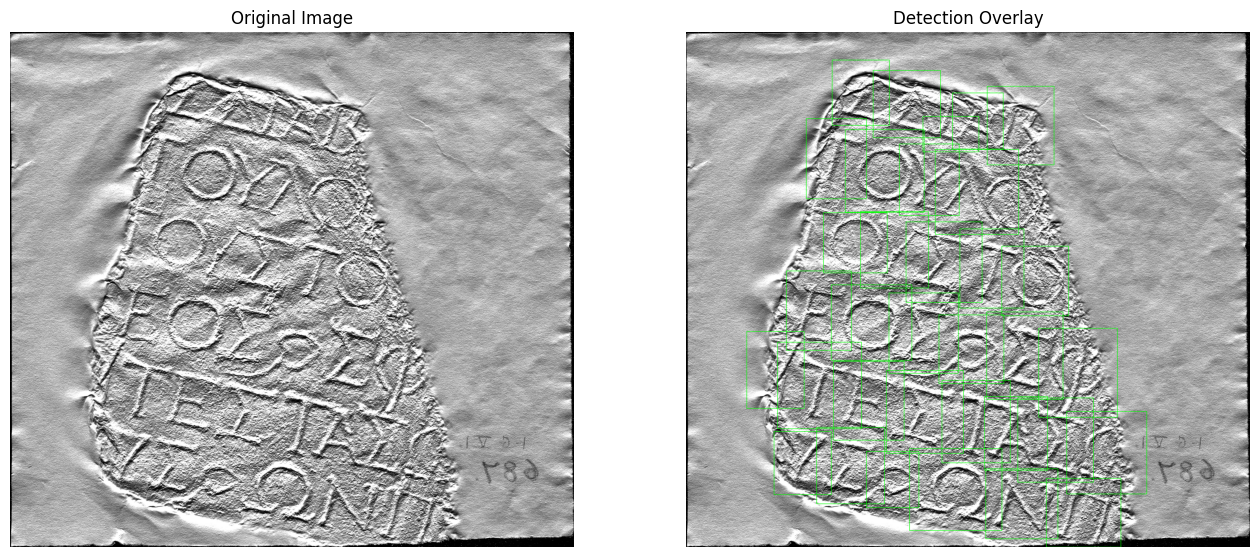

True

In [5]:
# Run SAHI detection on IMG1_PATH
print("Running SAHI detection on IMG1_PATH...")
result = get_sliced_prediction(IMG1_PATH, detection_model, slice_height=640, slice_width=640, overlap_height_ratio=0.2, overlap_width_ratio=0.2, postprocess_type="NMS")
boxes = result.object_prediction_list
print(f"Found {len(boxes)} boxes (raw).")

# Load image
img_cv2 = cv2.imread(IMG1_PATH)
img_rgb = cv2.cvtColor(img_cv2, cv2.COLOR_BGR2RGB)

# Draw overlay
overlay = draw_bboxes_on_image(img_cv2, boxes, color=(0,255,0), thickness=2)
overlay_rgb = cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)

# Show side-by-side
plt.figure(figsize=(16,8))
ax1 = plt.subplot(1,2,1)
ax1.imshow(img_rgb)
ax1.set_title('Original Image')
ax1.axis('off')

ax2 = plt.subplot(1,2,2)
ax2.imshow(overlay_rgb)
ax2.set_title('Detection Overlay')
ax2.axis('off')
plt.show()

# Save images for slide use
os.makedirs('outputs/slides', exist_ok=True)
cv2.imwrite('outputs/slides/original.png', img_cv2)
cv2.imwrite('outputs/slides/overlay.png', overlay)

## Extract top N crops and classify them

In [ ]:
# Select top 5 boxes by area (or score if available)
def box_area(pred):
    try:
        x1, y1, x2, y2 = map(int, pred.bbox.to_xyxy())
        return (x2 - x1) * (y2 - y1)
    except Exception:
        return 0

boxes_sorted = sorted(boxes, key=lambda p: getattr(p, 'score', box_area(p)), reverse=True)[:5]
crops = []
final_results = []
h_img, w_img, _ = img_cv2.shape

for p in boxes_sorted:
    try:
        x1, y1, x2, y2 = map(int, p.bbox.to_xyxy())
    except Exception:
        continue
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(w_img, x2), min(h_img, y2)
    if x2 <= x1 or y2 <= y1: continue
    crop_cv2 = img_cv2[y1:y2, x1:x2]
    # Preprocess and classify
    inp = cls_transforms(Image.fromarray(cv2.cvtColor(crop_cv2, cv2.COLOR_BGR2RGB))).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        out = classifier(inp)
        probs = F.softmax(out, dim=1)
        conf, pidx = torch.max(probs, 1)
    label = CLASS_NAMES[pidx.item()]
    confv = conf.item()
    crops.append((crop_cv2, label, confv))
    final_results.append({'x1': x1, 'y1': y1, 'x2': x2, 'y2': y2, 'label': label, 'conf': confv})

# Display crops with labels
n = len(crops)
cols = min(n, 5)
plt.figure(figsize=(12,3))
for i, (c, lab, cf) in enumerate(crops):
    ax = plt.subplot(1, cols, i+1)
    ax.imshow(cv2.cvtColor(c, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{lab} ({cf:.2f})")
    ax.axis('off')
plt.suptitle('Extracted Character Crops & Classifications')
plt.tight_layout()
plt.show()

# Save crops image
plt.savefig('outputs/slides/crops_grid.png', bbox_inches='tight')

## Reconstruct a short text snippet from classified boxes

In [ ]:
# Simple reconstruction: group by Y coordinate into lines, then sort by X
def reconstruct_transcript_simple(results, y_thresh=40):
    if not results: return ''
    items = [{'x': (r['x1']+r['x2'])/2, 'y': (r['y1']+r['y2'])/2, 'label': r['label']} for r in results]
    items.sort(key=lambda k: k['y'])
    lines = []
    current = [items[0]]
    for it in items[1:]:
        if abs(it['y'] - sum(c['y'] for c in current)/len(current)) <= y_thresh:
            current.append(it)
        else:
            current.sort(key=lambda k: k['x'])
            lines.append(''.join([c['label'] for c in current]))
            current = [it]
    if current:
        current.sort(key=lambda k: k['x'])
        lines.append(''.join([c['label'] for c in current]))
    return '\n'.join(lines)

snippet = reconstruct_transcript_simple(final_results)
print('--- Reconstructed Snippet ---')
print(snippet)
with open('outputs/slides/reconstructed_snippet.txt', 'w') as f:
    f.write(snippet)


## Slide-style summary figure (Original -> Crops -> Reconstructed text)

In [ ]:
# Create a single figure suitable for putting on a slide
fig = plt.figure(figsize=(18,6))
ax_left = plt.subplot2grid((2,6),(0,0),rowspan=2,colspan=2)
ax_mid = plt.subplot2grid((2,6),(0,2),rowspan=2,colspan=2)
ax_right = plt.subplot2grid((2,6),(0,4),rowspan=2,colspan=2)

# Left: overlay
ax_left.imshow(overlay_rgb)
ax_left.set_title('Detected Text Regions')
ax_left.axis('off')

# Middle: crops grid (replot thumbnails)
ax_mid.axis('off')
if crops:
    n = len(crops)
    thumb_h = 1.0 / max(1, n)
    for i, (c, lab, cf) in enumerate(crops):
        subax = fig.add_axes([0.33, 0.6 - i*0.18, 0.2, 0.15])
        subax.imshow(cv2.cvtColor(c, cv2.COLOR_BGR2RGB))
        subax.set_title(f"{lab} ({cf:.2f})", fontsize=9)
        subax.axis('off')
else:
    ax_mid.text(0.5, 0.5, 'No crops', ha='center', va='center')

# Right: reconstructed text
ax_right.axis('off')
ax_right.text(0.5, 0.5, snippet if snippet else 'No reconstructed text', ha='center', va='center', fontsize=12)
ax_right.set_title('Reconstructed Snippet')

plt.suptitle('Pipeline Overview: Detection -> Crops -> Classification -> Reconstruction')
plt.savefig('outputs/slides/pipeline_overview.png', bbox_inches='tight')
plt.show()

---
Files written to `outputs/slides/`: `original.png`, `overlay.png`, `crops_grid.png`, `reconstructed_snippet.txt`, and `pipeline_overview.png`.
You can open `notebooks/pipeline_for_slides.ipynb` to adjust or run the cells.